## 1. Model Training and Evaluation

In this section, five classification algorithms are trained and evaluated to predict machine failures. Stratified 5-fold cross-validation is used to compare model performance on the training data. The models are then evaluated on an independent test set using Accuracy, Precision, Recall, F1-score, and Balanced Accuracy.

In [9]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)



## 1. Load Prepared Datasets

In this section, the prepared training and testing datasets from Milestone 3 are loaded into the notebook. These datasets contain the processed features and the target variable required for machine learning.

## 2. Separate Features and Target

The input features (`X`) are separated from the target variable (`Machine failure`). The training dataset is used to train the models, while the testing dataset is kept separate to evaluate their performance on unseen data.


In [10]:
# Load prepared datasets
train_df = pd.read_csv(
    r"C:\Users\Asus\Desktop\ai4i-predictive-maintenance\milestone4\data\train_ready_milestone3.csv"
)

test_df = pd.read_csv(
    r"C:\Users\Asus\Desktop\ai4i-predictive-maintenance\milestone4\data\test_ready_milestone3.csv"
)

# Separate features and target
X_train = train_df.drop("Machine failure", axis=1)
y_train = train_df["Machine failure"]

X_test = test_df.drop("Machine failure", axis=1)
y_test = test_df["Machine failure"]

## Model Selection and Justification

Five classification algorithms were evaluated: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, Random Forest, and Gradient Boosting.

The models were compared using 5-fold stratified cross-validation and independent test-set metrics, including Accuracy, Precision, Recall, and F1-score.

The final model was selected based on its mean cross-validated F1-score. F1-score was considered important because predictive maintenance requires a balance between detecting failures and avoiding excessive false alarms.

The final selection should also consider missed failures, operational requirements, and the performance results reported above.

In [3]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Use the same stratified folds for all models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []
trained_models = {}
test_predictions = {}

# Train, validate, and evaluate each model
for name, model in models.items():

    print(f"Evaluating: {name}")

    # Evaluate the model using 5-fold cross-validation
    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    # Train the model on the full training set
    model.fit(X_train, y_train)

    # Predict failure on the test set
    y_pred = model.predict(X_test)

    # Save the trained model and its predictions
    trained_models[name] = model
    test_predictions[name] = y_pred

    # Store validation and test results
    results.append({
        "Model": name,
        "CV Accuracy": cv_results["test_accuracy"].mean(),
        "CV Precision": cv_results["test_precision"].mean(),
        "CV Recall": cv_results["test_recall"].mean(),
        "CV F1-score": cv_results["test_f1"].mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        )
    })

# Create a comparison table
results_df = pd.DataFrame(results)

# Select the model with the highest cross-validated F1-score
results_df = results_df.sort_values(
    by="CV F1-score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Identify the leading model using validation results
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = test_predictions[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: Highest mean 5-fold CV F1-score")

Evaluating: Logistic Regression
Evaluating: KNN
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: Gradient Boosting


,Model,CV Accuracy,CV Precision,CV Recall,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score,Balanced Accuracy
0,Random Forest,0.9705,0.9670,0.9009,0.9327,0.9708,0.9626,0.9067,0.9338,0.9482
1,Gradient Boosting,0.9658,0.9701,0.8767,0.9208,0.9668,0.9691,0.8820,0.9235,0.9369
2,Decision Tree,0.9462,0.8836,0.8794,0.8812,0.9428,0.8645,0.8873,0.8758,0.9232
3,KNN,0.9353,0.9558,0.7499,0.8402,0.9316,0.9501,0.7377,0.8305,0.8631
4,Logistic Regression,0.6993,0.4074,0.7111,0.5179,0.7040,0.4119,0.7077,0.5207,0.7053


Selected model: Random Forest
Selection criterion: Highest mean 5-fold CV F1-score



##  Model Performance Comparison

The performance of the five machine learning models is compared using Test Accuracy, Precision, Recall, and F1-score. This comparison helps identify the strengths and weaknesses of each model and evaluate its ability to detect machine failures. Multiple metrics are considered because Accuracy alone may not adequately reflect performance when failure cases are less frequent.


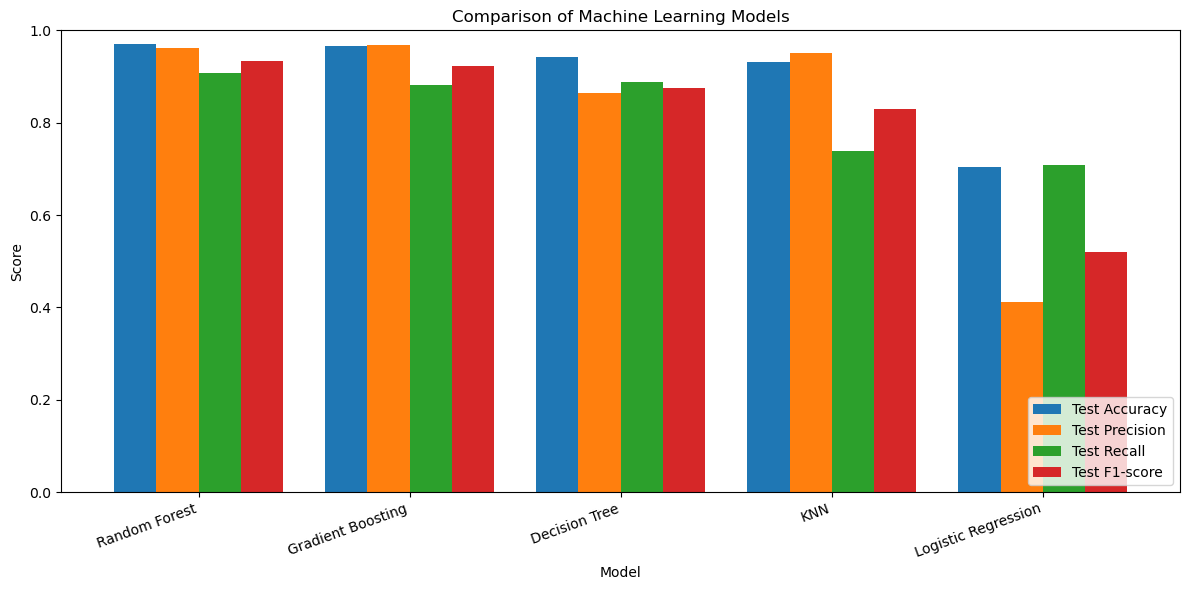

In [4]:

# Compare model performance using multiple metrics

metrics_to_plot = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1-score"
]

plot_data = results_df.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Comparison of Machine Learning Models")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()



##  Confusion Matrix and Classification Report

The confusion matrix evaluates the selected model by comparing actual machine failure labels with predicted labels. The classification report provides Precision, Recall, and F1-score for each class.

False negatives represent actual machine failures that the model fails to detect, while false positives represent false failure alerts. These results help assess the model's reliability and understand the potential risks of incorrect predictions in predictive maintenance.


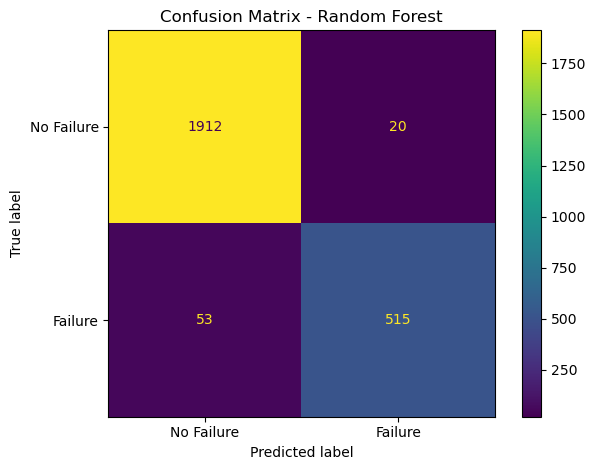

Classification Report: Random Forest

              precision    recall  f1-score   support

  No Failure       0.97      0.99      0.98      1932
     Failure       0.96      0.91      0.93       568

    accuracy                           0.97      2500
   macro avg       0.97      0.95      0.96      2500
weighted avg       0.97      0.97      0.97      2500

True Negatives (correctly predicted no failure): 1912
False Positives (false failure alerts): 20
False Negatives (missed failures): 53
True Positives (correctly detected failures): 515


In [5]:

# Display the confusion matrix for the selected model

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# Print detailed classification metrics
print(f"Classification Report: {best_model_name}\n")

print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["No Failure", "Failure"],
    zero_division=0
))

# Explain the confusion matrix values
tn, fp, fn, tp = cm.ravel()

print("True Negatives (correctly predicted no failure):", tn)
print("False Positives (false failure alerts):", fp)
print("False Negatives (missed failures):", fn)
print("True Positives (correctly detected failures):", tp)



##  Feature Importance Analysis

This section analyzes the importance of input features using the Random Forest model. The importance scores are extracted, sorted, and visualized to identify which features contribute most to the model's predictions of machine failure.

This analysis helps improve model interpretability and provides insights into the machine operating conditions associated with failure predictions. However, feature importance indicates predictive contribution and does not establish a causal relationship.


,Feature,Importance
3,Rotational speed [rpm],0.2006
6,Temp_Diff,0.1951
7,Mechanical_Power_W,0.1593
4,Torque [Nm],0.1447
5,Tool wear [min],0.1276
8,Strain_Index,0.0617
1,Air temperature [K],0.0555
2,Process temperature [K],0.0492
0,Type,0.0063


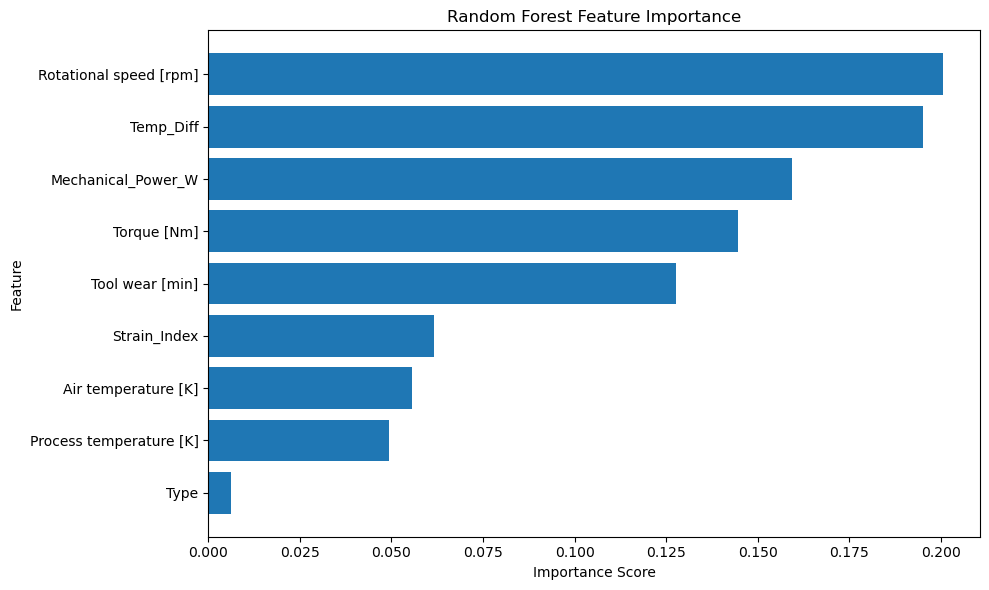

In [6]:

# Extract the Random Forest model for feature importance analysis

rf_model = trained_models["Random Forest"]

# Get feature importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

# Plot the most important features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



##  Prediction Results and Error Analysis

This section compares the actual machine failure labels with the predictions generated by the selected model. The results are presented in a table showing the actual class, predicted class, and whether each prediction is correct.

The analysis also identifies incorrectly classified cases to help understand the model's limitations and its ability to detect machine failures. Examining these errors can reveal opportunities for improving predictive maintenance performance.


In [12]:

# Compare actual and predicted results
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": best_predictions
})

# Check correct predictions
results["Correct"] = results["Actual"] == results["Predicted"]

# Display the first 20 predictions
display(results.head(20))

# Count correct and incorrect predictions
print("Correct predictions:", results["Correct"].sum())
print("Incorrect predictions:", (~results["Correct"]).sum())


,Actual,Predicted,Correct
0,1,1,True
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True


Correct predictions: 2427
Incorrect predictions: 73



##  Final Model Evaluation

This section summarizes the performance of the selected machine learning model on the independent test set. The evaluation includes Accuracy, Precision, Recall, F1-score, and Balanced Accuracy, along with the mean F1-score obtained through 5-fold cross-validation.

Random Forest was selected based on its highest mean cross-validated F1-score among the evaluated models. The final metrics provide an overview of its ability to predict machine failures and support the assessment of its suitability for predictive maintenance.


In [8]:

# Retrieve the selected model's test metrics

best_result = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print("=" * 50)
print("FINAL MODEL EVALUATION")
print("=" * 50)

print("Selected model:", best_model_name)
print(f"Cross-validation F1-score: {best_result['CV F1-score']:.4f}")
print(f"Test Accuracy: {best_result['Test Accuracy']:.4f}")
print(f"Test Precision: {best_result['Test Precision']:.4f}")
print(f"Test Recall: {best_result['Test Recall']:.4f}")
print(f"Test F1-score: {best_result['Test F1-score']:.4f}")
print(f"Balanced Accuracy: {best_result['Balanced Accuracy']:.4f}")

print("\nReason for selection:")
print(
    "The model was selected based on its highest mean "
    "5-fold cross-validated F1-score among the evaluated models."
)


FINAL MODEL EVALUATION
Selected model: Random Forest
Cross-validation F1-score: 0.9327
Test Accuracy: 0.9708
Test Precision: 0.9626
Test Recall: 0.9067
Test F1-score: 0.9338
Balanced Accuracy: 0.9482

Reason for selection:
The model was selected based on its highest mean 5-fold cross-validated F1-score among the evaluated models.
